# Task B – KNN Regressor

Predict the yearly number of extreme heat days (`hot_day_count`) and nights (`hot_night_count`) with KNN.


In [9]:
import pickle
from sklearn.neighbors import KNeighborsRegressor
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import pandas as pd
import matplotlib.pyplot as plt

data_root = "Final_SOCal_dataset.csv"   # change to your own path if needed

df = pd.read_csv(data_root)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65796 entries, 0 to 65795
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   station              65796 non-null  object 
 1   name                 65796 non-null  object 
 2   date                 65796 non-null  object 
 3   year                 65796 non-null  int64  
 4   tmin_lag1            65495 non-null  float64
 5   dtr_lag1             65212 non-null  float64
 6   dayofyear            65796 non-null  int64  
 7   days_since_rain      65796 non-null  float64
 8   oni_lag              65796 non-null  float64
 9   prcp_sum30           65571 non-null  float64
 10  prcp_lag1            65514 non-null  float64
 11  station_code         65796 non-null  int64  
 12  hot_day              65513 non-null  float64
 13  hot_night            65686 non-null  float64
 14  coverage             65796 non-null  float64
 15  prev_hot_nights      62717 non-null 

In [10]:
K = 11   # number of neighbors

def make_knn(features):
    numeric = [f for f in features if f != "station_code"]
    steps = [(StandardScaler(), numeric)]
    if "station_code" in features:
        steps.append((OneHotEncoder(handle_unknown="ignore"), ["station_code"]))
    prep = make_column_transformer(*steps)
    return make_pipeline(prep, KNeighborsRegressor(n_neighbors=K))

In [16]:
b_full_model = {}
for target in b_targets:
    model = make_knn(b_features)
    model.fit(b_train[b_features], b_train[target])
    b_full_model[target] = model
    print("Trained full model for", target)

Trained full model for hot_day_count
Trained full model for hot_night_count


In [13]:
b_features = ["prev_hot_nights", "prev_mean_tmin", "avg5_hot_days",
              "prev_max_spell_days", "station_code", "year"]
b_targets = ["hot_day_count", "hot_night_count"]

task_b = df.drop_duplicates(subset=["station", "year"])[b_features + b_targets]
print("Station-years before removing missing values:", len(task_b))
task_b = task_b.dropna()
print("Station-years after removing missing values: ", len(task_b))

Station-years before removing missing values: 359
Station-years after removing missing values:  329


In [14]:
train_end = 2015
b_train = task_b[task_b["year"] <= train_end]
b_test = task_b[task_b["year"] > train_end]
print("Train rows:", len(b_train))
print("Test rows: ", len(b_test))

Train rows: 281
Test rows:  48


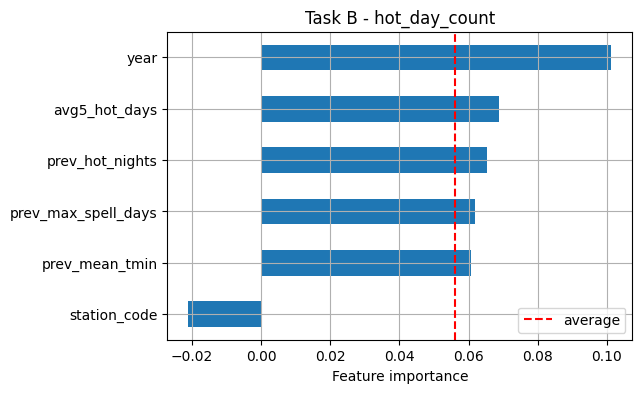

hot_day_count selected features: ['year', 'avg5_hot_days', 'prev_hot_nights', 'prev_max_spell_days', 'prev_mean_tmin']


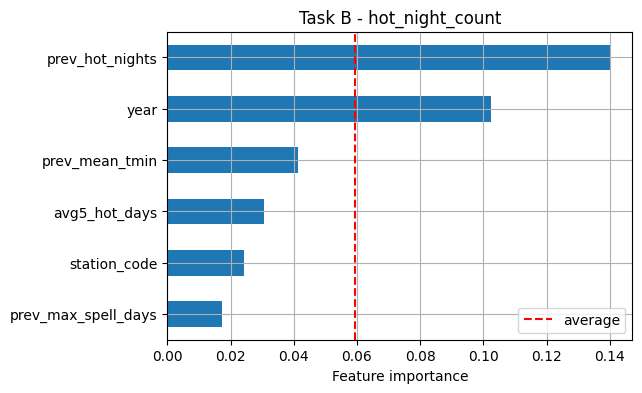

hot_night_count selected features: ['prev_hot_nights', 'year']


In [17]:
b_selected = {}
for target in b_targets:
    result = permutation_importance(
        b_full_model[target], b_train[b_features], b_train[target], n_repeats=10, random_state=42
    )
    importance = pd.Series(result.importances_mean, index=b_features).sort_values()
    importance.plot(kind="barh", figsize=(6, 4), grid=True)
    plt.axvline(importance.mean(), color="r", linestyle="--", label="average")
    plt.title(f"Task B - {target}")
    plt.xlabel("Feature importance")
    plt.legend()
    plt.show()
    b_selected[target] = importance[importance >= importance.mean()].sort_values(ascending=False).index.tolist()
    print(target, "selected features:", b_selected[target])

In [18]:
b_reduced_models = {}
for target in b_targets:
    features = b_selected[target]
    model = make_knn(features)
    model.fit(b_train[features], b_train[target])
    b_reduced_models[target] = model
    print("Trained reduced model for", target, "with", len(features), "features")

Trained reduced model for hot_day_count with 5 features
Trained reduced model for hot_night_count with 2 features


In [19]:
saved_models = []   # (file name, test X, test y)

for target in b_targets:
    filename = f"taskB_knn_{target}_full.sav"
    pickle.dump(b_full_model[target], open(filename, "wb"))
    saved_models.append((filename, b_test[b_features], b_test[target]))

    filename = f"taskB_knn_{target}_reduced.sav"
    pickle.dump(b_reduced_models[target], open(filename, "wb"))
    saved_models.append((filename, b_test[b_selected[target]], b_test[target]))

for filename, X_test, y_test in saved_models:
    loaded_model = pickle.load(open(filename, "rb"))
    result = loaded_model.score(X_test, y_test)
    print(f"{filename:40s} {result:.3f}")

taskB_knn_hot_day_count_full.sav         -0.117
taskB_knn_hot_day_count_reduced.sav      -0.124
taskB_knn_hot_night_count_full.sav       0.176
taskB_knn_hot_night_count_reduced.sav    0.096
